In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup as bs
import requests as rq

In [2]:
url='https://quotes.toscrape.com'

In [3]:
s=rq.get(url)
s

<Response [200]>

In [4]:
io=bs(s.text,'html.parser')    

In [5]:
data=io.find_all('div' , class_='quote')

In [6]:
web=[]

for i in data:
    quote=i.find('span',class_='text').text
    author=i.find('small',class_='author').text
    tag=i.find('div',class_='tags').text.split(' ')[-1].replace('\n', ', ').strip(', ')
    
    web.append({'Quotes':quote,'Authors':author,'Tags':tag})
    

In [7]:
df=pd.DataFrame(web)

In [8]:
df['Quote Length']=df['Quotes'].str.len()

In [9]:
df['Word Count']=df['Quotes'].str.split().str.len()

In [10]:
df['Tag Count']=df['Tags'].str.split(', ').str.len()

In [11]:
author_info = {
    "Albert Einstein": {
        "Birth Year": 1879,
        "Nationality": "German-born",
        "Profession": "Physicist",
        "Famous Work": "Relativity: The Special and the General Theory",
        "Work Type": "Book"
    },

    "J.K. Rowling": {
        "Birth Year": 1965,
        "Nationality": "British",
        "Profession": "Author",
        "Famous Work": "Harry Potter and the Philosopher's Stone",
        "Work Type": "Novel"
    },

    "Jane Austen": {
        "Birth Year": 1775,
        "Nationality": "British",
        "Profession": "Novelist",
        "Famous Work": "Pride and Prejudice",
        "Work Type": "Novel"
    },

    "Marilyn Monroe": {
        "Birth Year": 1926,
        "Nationality": "American",
        "Profession": "Actress",
        "Famous Work": "My Story",
        "Work Type": "Autobiography"
    },

    "Steve Martin": {
        "Birth Year": 1945,
        "Nationality": "American",
        "Profession": "Actor & Comedian",
        "Famous Work": "Born Standing Up",
        "Work Type": "Memoir"
    },

    "Eleanor Roosevelt": {
        "Birth Year": 1884,
        "Nationality": "American",
        "Profession": "Writer & Diplomat",
        "Famous Work": "You Learn by Living",
        "Work Type": "Book"
    }
}

In [12]:
birth_year = {}

for a in author_info:
    birth_year[a] = author_info[a]["Birth Year"]

df["Birth Year"] = df["Authors"].map(birth_year)

In [13]:
nationality = {}

for b in author_info:
    nationality[b] = author_info[b]["Nationality"]

df["Nationality"] = df["Authors"].map(nationality)

In [14]:
profession = {}

for c in author_info:
    profession[c] = author_info[c]["Profession"]

df["Profession"] = df["Authors"].map(profession)

In [15]:
famous_work = {}

for d in author_info:
    famous_work[d] = author_info[d]["Famous Work"]

df["Famous Work"] = df["Authors"].map(famous_work)

In [16]:
work_type = {}

for e in author_info:
    work_type[e] = author_info[e]["Work Type"]

df["Work Type"] = df["Authors"].map(work_type)

In [17]:
df=df.dropna()

In [18]:
df=df[['Authors','Birth Year','Nationality','Profession','Quotes','Quote Length','Word Count','Tags','Tag Count','Famous Work','Work Type']]
df

,Authors,Birth Year,Nationality,Profession,Quotes,Quote Length,Word Count,Tags,Tag Count,Famous Work,Work Type
0,Albert Einstein,1879.0,German-born,Physicist,“The world as we have created it is a process ...,115,21,"change, deep-thoughts, thinking, world",4,Relativity: The Special and the General Theory,Book
1,J.K. Rowling,1965.0,British,Author,"“It is our choices, Harry, that show what we t...",85,16,"abilities, choices",2,Harry Potter and the Philosopher's Stone,Novel
2,Albert Einstein,1879.0,German-born,Physicist,“There are only two ways to live your life. On...,131,26,"inspirational, life, live, miracle, miracles",5,Relativity: The Special and the General Theory,Book
3,Jane Austen,1775.0,British,Novelist,"“The person, be it gentleman or lady, who has ...",104,19,"aliteracy, books, classic, humor",4,Pride and Prejudice,Novel
4,Marilyn Monroe,1926.0,American,Actress,"“Imperfection is beauty, madness is genius and...",111,16,"be-yourself, inspirational",2,My Story,Autobiography
5,Albert Einstein,1879.0,German-born,Physicist,“Try not to become a man of success. Rather be...,67,14,"adulthood, success, value",3,Relativity: The Special and the General Theory,Book
8,Eleanor Roosevelt,1884.0,American,Writer & Diplomat,“A woman is like a tea bag; you never know how...,85,19,misattributed-eleanor-roosevelt,1,You Learn by Living,Book
9,Steve Martin,1945.0,American,Actor & Comedian,"“A day without sunshine is like, you know, nig...",50,9,"humor, obvious, simile",3,Born Standing Up,Memoir


/var/folders/g1/zvnj8krj591_9hdt4c66zgr00000gn/T/ipykernel_1363/2057961044.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  e=sns.barplot(a,x='Work Type',y='count',palette='coolwarm',edgecolor='violet',linewidth=2)


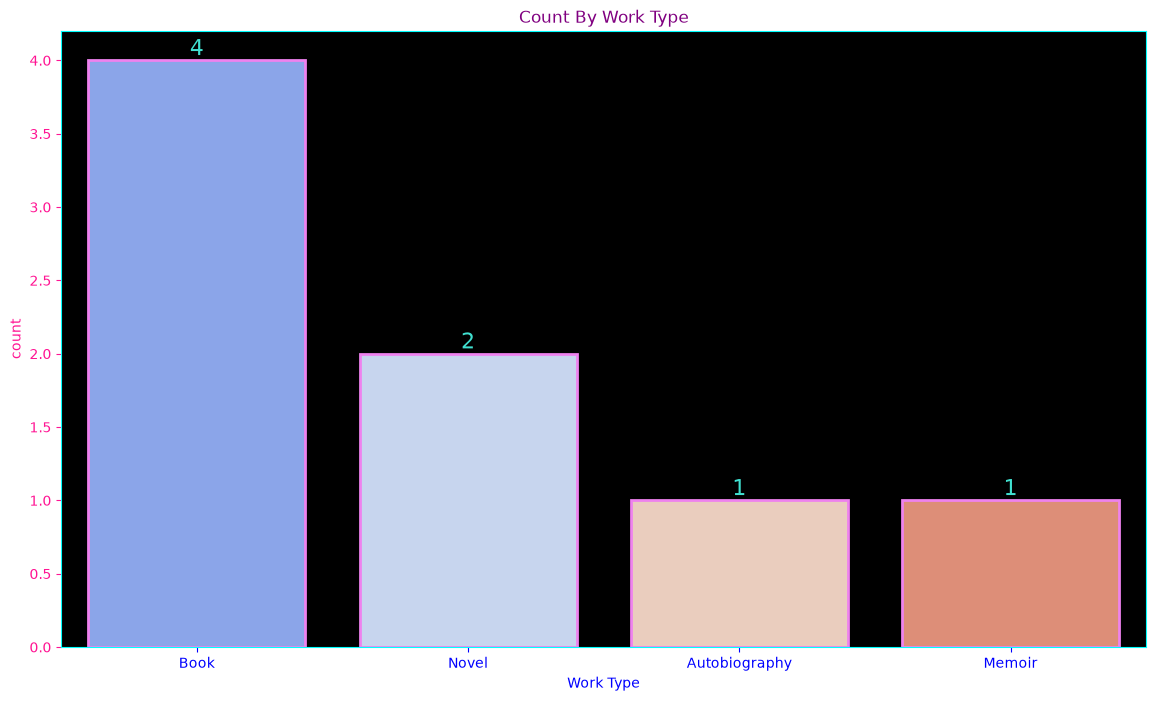

In [19]:
a=df['Work Type'].value_counts().reset_index()

plt.figure(figsize=(14,8))
e=sns.barplot(a,x='Work Type',y='count',palette='coolwarm',edgecolor='violet',linewidth=2)
e.set_facecolor('black')
e.xaxis.label.set_color('blue')
e.yaxis.label.set_color('deeppink')
e.spines['top'].set_color('cyan')
e.spines['bottom'].set_color('cyan')
e.spines['left'].set_color('cyan')
e.spines['right'].set_color('cyan')
plt.tick_params(axis='x',color='blue')
plt.tick_params(axis='y',color='deeppink')
plt.xticks(color='blue')
plt.yticks(color='deeppink')
e.set_title('Count By Work Type',color='purple')
for i in e.containers:
    e.bar_label(i,color='turquoise',fontsize=16)

In [20]:
def z(data,n):
    a=df[n].value_counts().reset_index()
    plt.figure(figsize=(12,8))
    e=sns.barplot(a,y=n,x='count',color='cyan')
    e.xaxis.label.set_color('blue')
    e.yaxis.label.set_color('red')
    e.spines['top'].set_color('deeppink')
    e.spines['bottom'].set_color('deeppink')
    e.spines['left'].set_color('deeppink')
    e.spines['right'].set_color('deeppink')
    plt.tick_params(axis='x',color='blue')
    plt.tick_params(axis='y',color='red')
    plt.xticks(color='blue')
    plt.yticks(color='red')
    e.set_title(f'Count By {n}', color='midnightblue')
    for i in e.containers:
        e.bar_label(i,color='navy')

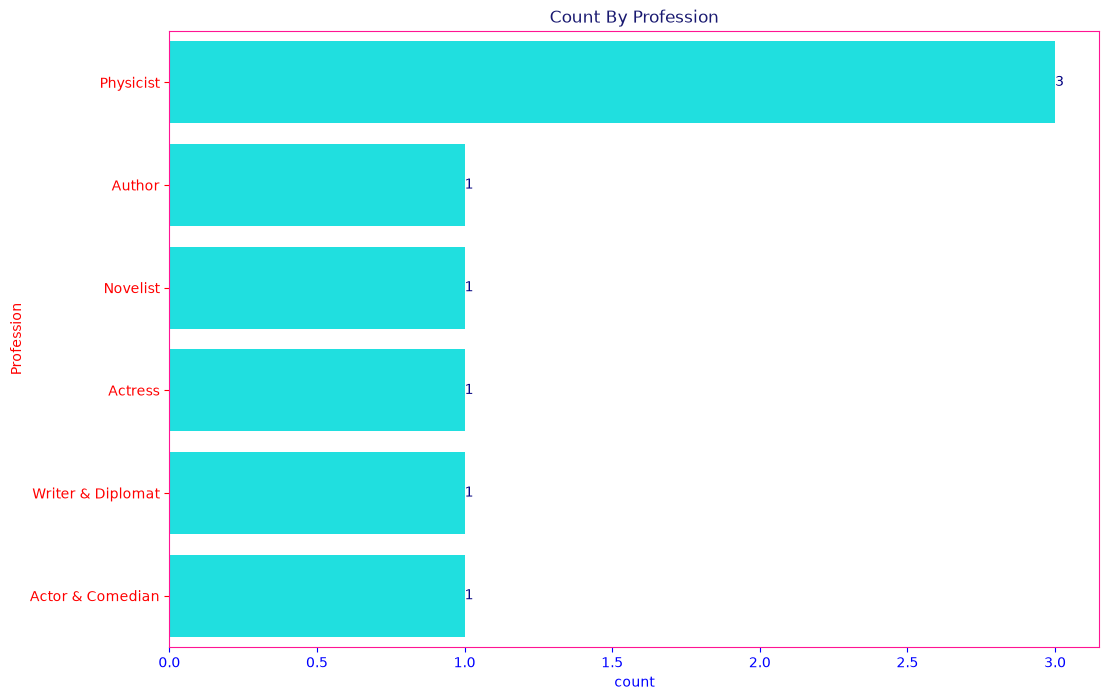

In [21]:
z(data,'Profession')

/var/folders/g1/zvnj8krj591_9hdt4c66zgr00000gn/T/ipykernel_1363/1100693828.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  s=sns.barplot(b, y='Authors', x='Quote Length',palette='Set1')


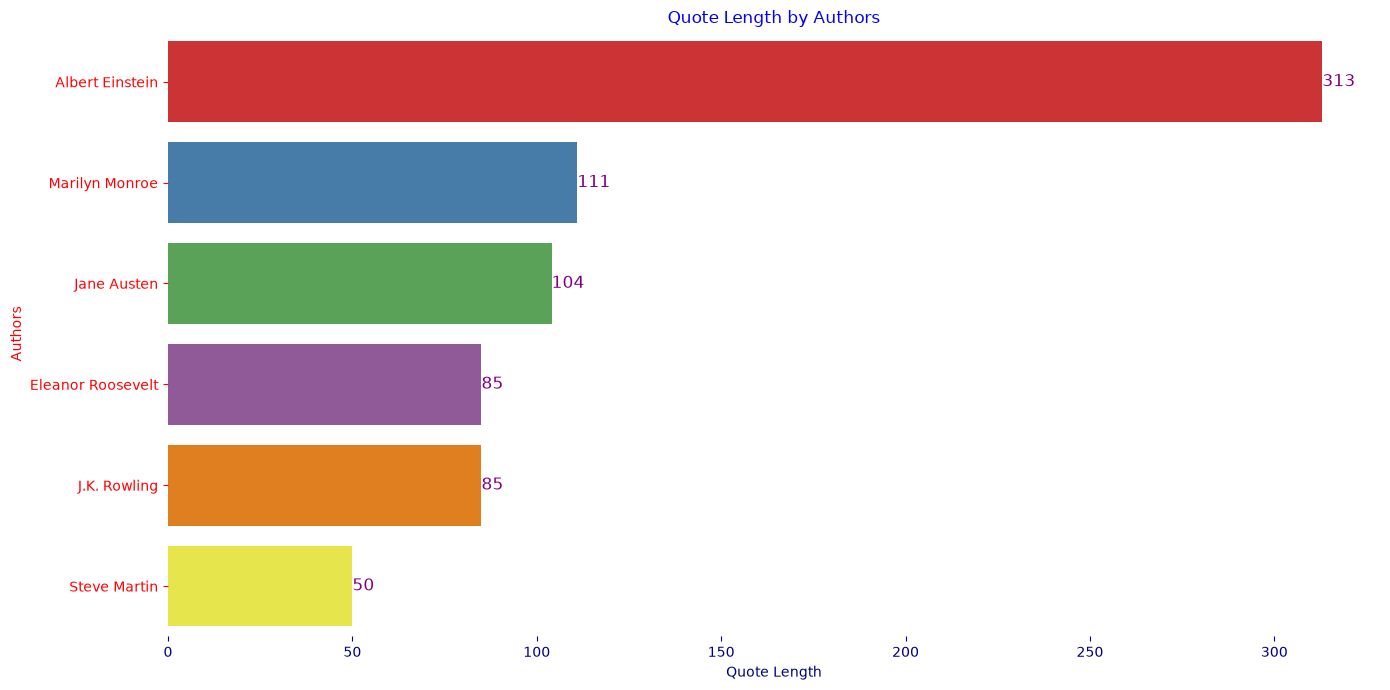

In [22]:
b=df.groupby(['Authors'],as_index=False)['Quote Length'].sum().sort_values(by='Quote Length',ascending=False)

plt.figure(figsize=(14,7))
s=sns.barplot(b, y='Authors', x='Quote Length',palette='Set1')
s.set_title('Quote Length by Authors',color='blue')
s.xaxis.label.set_color('navy')
s.yaxis.label.set_color('red')
plt.tick_params(axis='x',color='navy')
plt.tick_params(axis='y',color='red')
plt.xticks(color='navy')
plt.yticks(color='red')
sns.despine(right=True,left=True,top=True,bottom=True)
plt.tight_layout()
for i in s.containers:
    s.bar_label(i,fontsize=12,color='purple')
plt.show()

In [34]:
def visual(data,a,b):
    z=data.groupby([a], as_index=False)[b].sum().sort_values(by=b, ascending=False)
    plt.figure(figsize=(18,7))
    n=sns.barplot(z,x=b,y=a,palette='viridis')
    n.set_facecolor('lavender')
    n.spines['top'].set_color('purple')
    n.spines['bottom'].set_color('purple')
    n.spines['left'].set_color('purple')
    n.spines['right'].set_color('purple')
    n.xaxis.label.set_color('navy')
    n.yaxis.label.set_color('red')
    plt.tick_params(axis='x',color='navy')
    plt.tick_params(axis='y',color='red')
    plt.xticks(color='navy')
    plt.yticks(color='red')
    n.set_title(f'{b} by {a}',color='blue')
    for i in n.containers:
        n.bar_label(i,fmt='%.0f',color='mediumvioletred',fontsize=12)

/var/folders/g1/zvnj8krj591_9hdt4c66zgr00000gn/T/ipykernel_1363/3814714509.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  n=sns.barplot(z,x=b,y=a,palette='viridis')


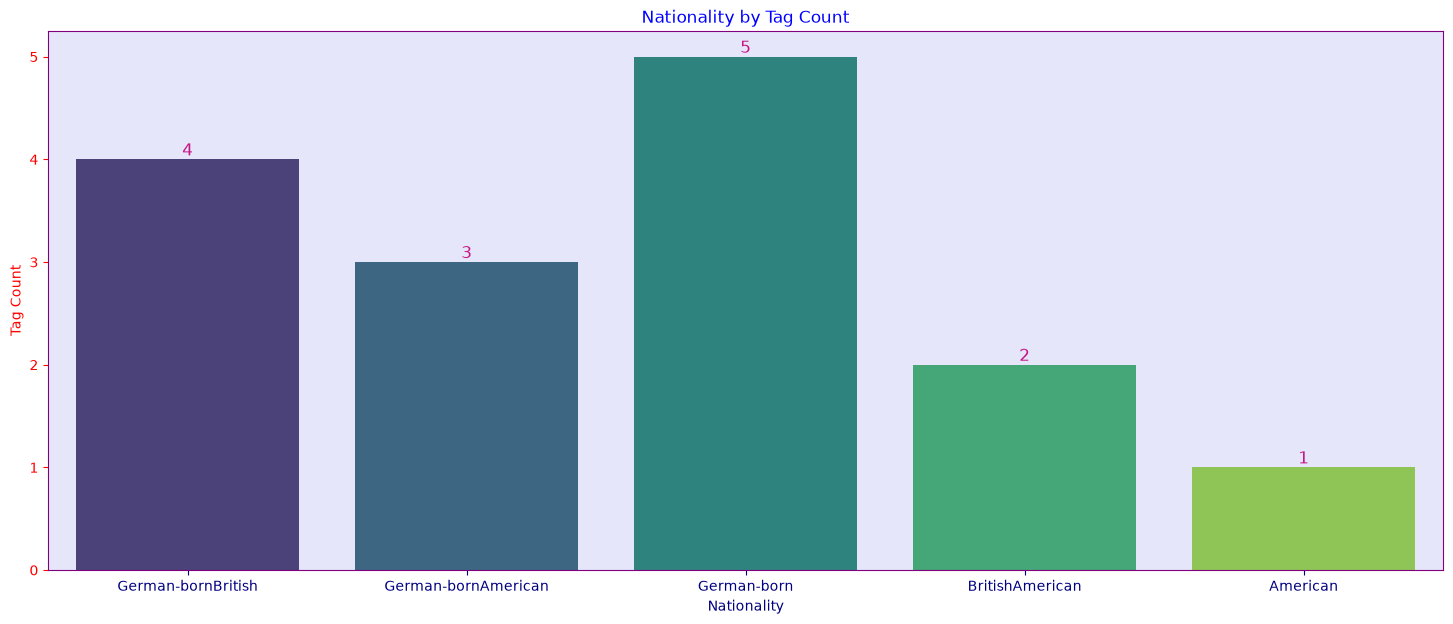

In [35]:
visual(df,'Tag Count','Nationality')

In [25]:
textp_w=''.join(df['Tags'].dropna().astype(str))
from wordcloud import STOPWORDS
stopwords=set(STOPWORDS)

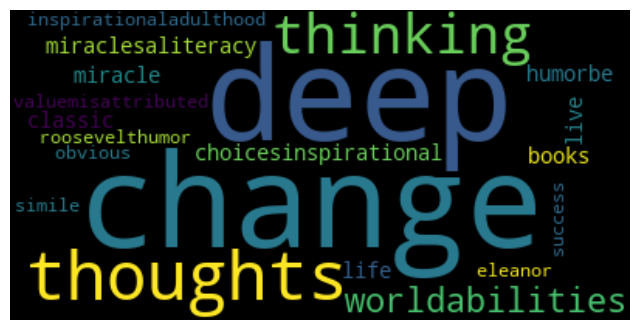

In [33]:
from wordcloud import WordCloud
wc= WordCloud(background_color="black", max_words=len(textp_w), stopwords=stopwords)
wc.generate(textp_w)
plt.figure(figsize=(8,5))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.show()